# Feed-Forward Neural Network

Train and evaluate a feed-forward neural network using TF-IDF features to classify human and ChatGPT-generated text.

In [37]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

import json

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
)

## Load Data and TF-IDF Features

Load the saved TF-IDF vectorizer and the train, validation, and test datasets.

In [38]:
PROJECT_ROOT = Path("../..")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODELS_DIR = PROJECT_ROOT / "models"
TFIDF_MODEL_DIR = MODELS_DIR / "tfidf"

In [39]:
vectorizer = joblib.load(
    TFIDF_MODEL_DIR / "tfidf_vectorizer.joblib"
)


train = pd.read_csv(PROCESSED_DIR / "train.csv")
validation = pd.read_csv(PROCESSED_DIR / "validation.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

print(train.shape, validation.shape, test.shape)

(58823, 6) (12611, 6) (12632, 6)


## Prepare Data for Training

Transform the text into TF-IDF features and create batch generators for training, validation, and testing.

In [40]:
X_train = vectorizer.transform(train["text"].astype(str))
X_val = vectorizer.transform(validation["text"].astype(str))
X_test = vectorizer.transform(test["text"].astype(str))

y_train = train["target"].astype(int)
y_val = validation["target"].astype(int)
y_test = test["target"].astype(int)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (58823, 100000)
Validation: (12611, 100000)
Test: (12632, 100000)


In [41]:
class SparseBatchGenerator(keras.utils.Sequence):
    def __init__(self, X, y, batch_size=128, shuffle=True):
        super().__init__()
        self.X = X
        self.y = np.asarray(y, dtype=np.float32)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(X.shape[0])
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = min((index + 1) * self.batch_size, len(self.indices))

        batch_indices = self.indices[start:end]

        X_batch = self.X[batch_indices].toarray().astype(np.float32)
        y_batch = self.y[batch_indices]

        return X_batch, y_batch

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

In [42]:
BATCH_SIZE = 128

train_gen = SparseBatchGenerator(
    X_train,
    y_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_gen = SparseBatchGenerator(
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_gen = SparseBatchGenerator(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

## Build the Neural Network

Define the feed-forward neural network architecture and training settings.

In [43]:
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

In [44]:
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),

    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │     6,400,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,402,177 (24.42 MB)

 Trainable params: 6,402,177 (24.42 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
model.compile(
    optimizer=keras.optimizers.Adam(
    learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
    "accuracy",
    keras.metrics.AUC(name="auc")
]
)

In [46]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

## Balance Class Weights

Calculate class weights so the model accounts for the larger number of human examples in the training data.

In [47]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.7348465920447731), np.int64(1): np.float64(1.5645247087611043)}


## Train the Model

Train the neural network using the TF-IDF features and monitor validation loss with early stopping.

In [48]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=[early_stopping],
    class_weight=class_weights,
    verbose=2
)

Epoch 1/20
460/460 - 8s - 17ms/step - accuracy: 0.8038 - auc: 0.9541 - loss: 0.5439 - val_accuracy: 0.9587 - val_auc: 0.9948 - val_loss: 0.3516
Epoch 2/20
460/460 - 7s - 15ms/step - accuracy: 0.9693 - auc: 0.9955 - loss: 0.2078 - val_accuracy: 0.9818 - val_auc: 0.9982 - val_loss: 0.1275
Epoch 3/20
460/460 - 7s - 15ms/step - accuracy: 0.9858 - auc: 0.9986 - loss: 0.0898 - val_accuracy: 0.9863 - val_auc: 0.9988 - val_loss: 0.0685
Epoch 4/20
460/460 - 7s - 15ms/step - accuracy: 0.9919 - auc: 0.9995 - loss: 0.0499 - val_accuracy: 0.9876 - val_auc: 0.9990 - val_loss: 0.0476
Epoch 5/20
460/460 - 7s - 15ms/step - accuracy: 0.9955 - auc: 0.9998 - loss: 0.0304 - val_accuracy: 0.9881 - val_auc: 0.9991 - val_loss: 0.0384
Epoch 6/20
460/460 - 7s - 16ms/step - accuracy: 0.9973 - auc: 0.9999 - loss: 0.0199 - val_accuracy: 0.9888 - val_auc: 0.9991 - val_loss: 0.0339
Epoch 7/20
460/460 - 7s - 16ms/step - accuracy: 0.9985 - auc: 0.9999 - loss: 0.0134 - val_accuracy: 0.9892 - val_auc: 0.9991 - val_loss:

## Evaluate on validation data
Evaluate the model on the training set to compare training performance with validation and test results.

In [49]:
val_probs = model.predict(val_gen, verbose=0).ravel()

val_preds = (val_probs >= 0.5).astype(int)

In [50]:
fpr, tpr, thresholds = roc_curve(y_val, val_probs)
val_roc_auc = roc_auc_score(y_val, val_probs)

print(f"Validation Accuracy: {accuracy_score(y_val, val_preds):.4f}")

print(f"Validation Macro Precision: {precision_score(y_val, val_preds, average='macro', zero_division=0):.4f}")

print(f"Validation Macro Recall: {recall_score(y_val, val_preds, average='macro', zero_division=0):.4f}")

print(f"Validation Macro F1: {f1_score(y_val, val_preds, average='macro', zero_division=0):.4f}")

print(f"Validation ROC-AUC: {val_roc_auc:.4f}")

print("\nConfusion Matrix:\n",
    confusion_matrix(y_val,val_preds,),
)

Validation Accuracy: 0.9895
Validation Macro Precision: 0.9896
Validation Macro Recall: 0.9863
Validation Macro F1: 0.9879
Validation ROC-AUC: 0.9992

Confusion Matrix:
 [[8538   40]
 [  92 3941]]


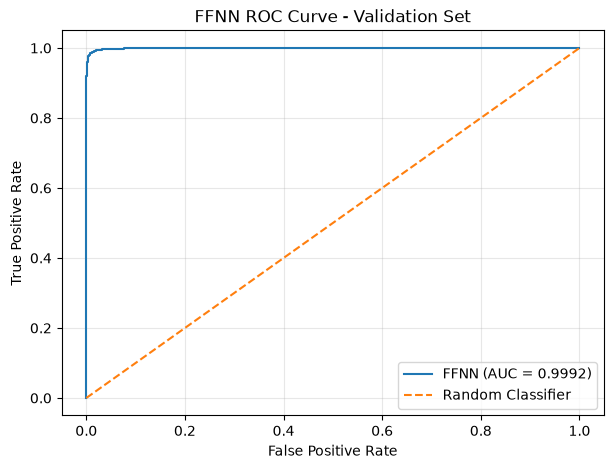

In [51]:
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"FFNN (AUC = {val_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("FFNN ROC Curve - Validation Set")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

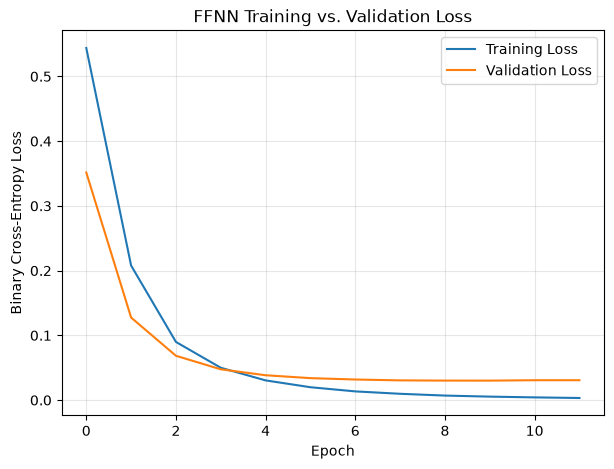

In [52]:
plt.figure(figsize=(7, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("FFNN Training vs. Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

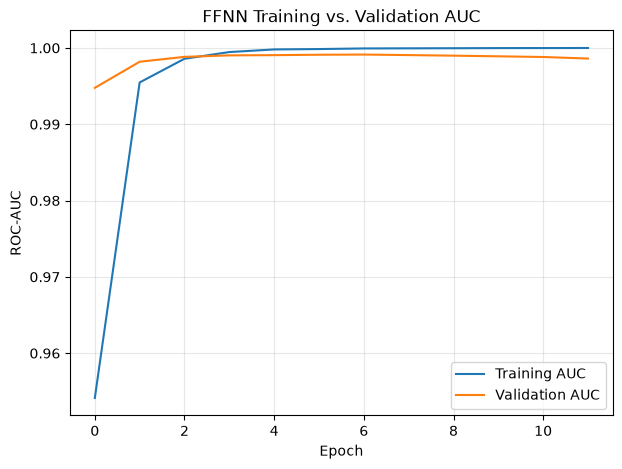

In [53]:
plt.figure(figsize=(7, 5))

plt.plot(history.history["auc"], label="Training AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("FFNN Training vs. Validation AUC")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Evaluate on the test data
Evaluate the final model on the held-out test set to measure performance on unseen data.

In [54]:
test_probs = model.predict(
    test_gen,
    verbose=0,
).ravel()

test_preds = (
    test_probs >= 0.5
).astype(int)

print(
    f"Test Accuracy:        "
    f"{accuracy_score(y_test, test_preds):.4f}"
)
print(
    f"Test Macro Precision: "
    f"{precision_score(y_test, test_preds, average='macro', zero_division=0):.4f}"
)
print(
    f"Test Macro Recall:    "
    f"{recall_score(y_test, test_preds, average='macro', zero_division=0):.4f}"
)
print(
    f"Test Macro F1:        "
    f"{f1_score(y_test, test_preds, average='macro', zero_division=0):.4f}"
)
print(
    f"Test ROC-AUC:         "
    f"{roc_auc_score(y_test, test_probs):.4f}"
)

print(
    "\n"
    + classification_report(
        y_test,
        test_preds,
        target_names=[
            "Human",
            "ChatGPT",
        ],
        zero_division=0,
    )
)

Test Accuracy:        0.9896
Test Macro Precision: 0.9888
Test Macro Recall:    0.9872
Test Macro F1:        0.9880
Test ROC-AUC:         0.9994

              precision    recall  f1-score   support

       Human       0.99      0.99      0.99      8579
     ChatGPT       0.99      0.98      0.98      4053

    accuracy                           0.99     12632
   macro avg       0.99      0.99      0.99     12632
weighted avg       0.99      0.99      0.99     12632



Test Confusion Matrix:
[[8526   53]
 [  79 3974]]


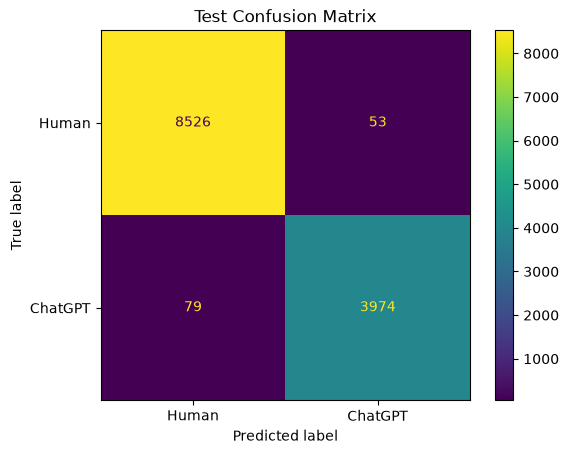

In [58]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_cm = confusion_matrix(y_test, test_preds)

print("Test Confusion Matrix:")
print(test_cm)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, test_preds),
    display_labels=["Human", "ChatGPT"]
).plot()

plt.title("Test Confusion Matrix")
plt.show()

### Save the neural network
Save the trained neural network and its metadata for reuse and comparison with other models.

In [55]:
model_path = (
    TFIDF_MODEL_DIR
    / "feedforward_neural_network.keras"
)

metadata_path = (
    TFIDF_MODEL_DIR
    / "feedforward_neural_network_metadata.json"
)

model.save(model_path)

metadata = {
    "threshold": 0.5,
    "vectorizer": "tfidf_vectorizer.joblib",
    "learning_rate": 0.0001,
    "batch_size": BATCH_SIZE,
    "architecture": [64, 32, 1],
}

with open(
    metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata,
        file,
        indent=2,
    )

print(f"Saved neural network to {model_path}")
print(f"Saved metadata to {metadata_path}")

Saved neural network to ../../models/tfidf/feedforward_neural_network.keras
Saved metadata to ../../models/tfidf/feedforward_neural_network_metadata.json
